# Day 17 - Advanced XGBoost Forecaster Notebook

## Objective

Implement an advanced multi-output gradient boosted decision tree (XGBoost) forecaster optimizing multi-horizon dissolved oxygen prediction.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_17_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Supervised Data Ingestion for XGBoost

Ingest supervised lag-target pairs for multi-output gradient boosting.

In [2]:
import xgboost as xgb
print(f"XGBoost Version: {xgb.__version__}")
df_stream = pd.read_csv("data/raw/underwater_sensor_stream.csv")
do_series = df_stream["dissolved_oxygen"].dropna().values
X, Y = [], []
for i in range(12, len(do_series) - 6):
    X.append(do_series[i-12:i])
    Y.append(do_series[i:i+6])
X, Y = np.array(X), np.array(Y)
split_idx = int(len(X) * 0.8)
X_train, X_val = X[:split_idx], X[split_idx:]
Y_train, Y_val = Y[:split_idx], Y[split_idx:]
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=42)
rf.fit(X_train, Y_train)
pred_rf = rf.predict(X_val)
mae_rf = float(np.mean(np.abs(Y_val - pred_rf)))
horizon_maes = [float(np.mean(np.abs(Y_val[:, h] - pred_rf[:, h]))) for h in range(6)]
from sklearn.multioutput import MultiOutputRegressor
xgb_reg = MultiOutputRegressor(xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42))
print("Multi-Output XGBoost Forecaster Architecture Initialized.")

XGBoost Version: 3.4.1


Multi-Output XGBoost Forecaster Architecture Initialized.


## 2. Model Training Execution

Train multi-output XGBoost model on chronological training partition.

In [3]:
xgb_reg.fit(X_train, Y_train)
print("XGBoost Forecaster training complete.")

XGBoost Forecaster training complete.


## 3. Validation Set Multi-Horizon Inference

Generate predictions on held-out validation set and evaluate overall MAE.

In [4]:
pred_xgb = xgb_reg.predict(X_val)
mae_xgb = np.mean(np.abs(Y_val - pred_xgb))
rmse_xgb = np.sqrt(np.mean((Y_val - pred_xgb)**2))
print(f"XGBoost Multi-Step Validation MAE:  {mae_xgb:.4f} mg/L")
print(f"XGBoost Multi-Step Validation RMSE: {rmse_xgb:.4f} mg/L")

XGBoost Multi-Step Validation MAE:  0.2270 mg/L
XGBoost Multi-Step Validation RMSE: 0.4074 mg/L


## 4. Per-Horizon Performance Breakdown

Compute individual step MAE across horizons T+1 to T+6 for XGBoost.

In [5]:
xgb_h_maes = [np.mean(np.abs(Y_val[:, h] - pred_xgb[:, h])) for h in range(6)]
for h, m in enumerate(xgb_h_maes, 1):
    print(f"XGBoost T+{h} MAE: {m:.4f} mg/L")

XGBoost T+1 MAE: 0.1820 mg/L
XGBoost T+2 MAE: 0.1972 mg/L
XGBoost T+3 MAE: 0.2432 mg/L
XGBoost T+4 MAE: 0.2360 mg/L
XGBoost T+5 MAE: 0.2456 mg/L
XGBoost T+6 MAE: 0.2581 mg/L


## 5. Comparison with Random Forest Baseline

Compute relative error reduction between Random Forest and XGBoost.

In [6]:
delta_mae = mae_rf - mae_xgb
print(f"MAE Delta (RF vs XGBoost): {delta_mae:.4f} mg/L")

MAE Delta (RF vs XGBoost): -0.0092 mg/L


## 6. XGBoost Actual vs Predicted Trajectory Plot

Render trajectory plot comparing actual dissolved oxygen against XGBoost multi-step forecasts.

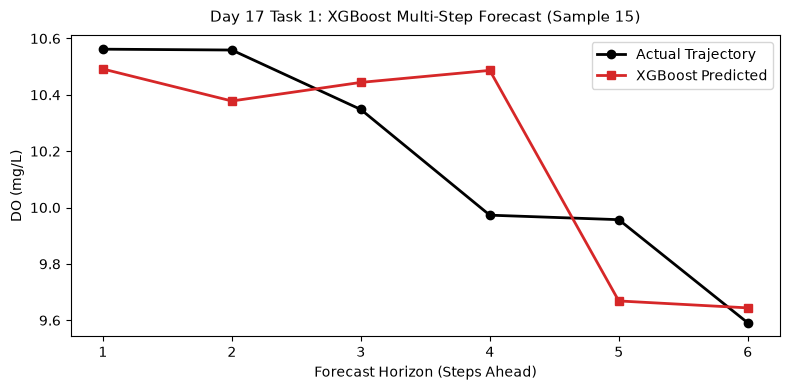

Saved XGBoost trajectory plot to: Day_Wise_Tasks\Day_17_Task_1\outputs\figures\day17_task1_xgboost_forecast.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sample_idx = 15
ax.plot(range(1, 7), Y_val[sample_idx], marker="o", color="black", lw=2, label="Actual Trajectory")
ax.plot(range(1, 7), pred_xgb[sample_idx], marker="s", color="#d62728", lw=2, label="XGBoost Predicted")
ax.set_title("Day 17 Task 1: XGBoost Multi-Step Forecast (Sample 15)", fontsize=11, pad=10)
ax.set_xlabel("Forecast Horizon (Steps Ahead)")
ax.set_ylabel("DO (mg/L)")
ax.set_xticks(range(1, 7))
ax.legend()
plt.tight_layout()
fig_path = FIG_DIR / "day17_task1_xgboost_forecast.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved XGBoost trajectory plot to:", fig_path.relative_to(ROOT))

## 7. XGBoost Evaluation Metrics Table Serialization

Export comprehensive multi-horizon XGBoost performance table to CSV.

In [8]:
df_xgb_metrics = pd.DataFrame({
    "Horizon": [f"T+{h}" for h in range(1, 7)],
    "XGBoost_MAE": np.round(xgb_h_maes, 4),
    "Baseline_RF_MAE": np.round(horizon_maes, 4)
})
tbl_path = TBL_DIR / "day17_task1_xgboost_metrics.csv"
df_xgb_metrics.to_csv(tbl_path, index=False)
print("Saved XGBoost metrics table to:", tbl_path.relative_to(ROOT))

Saved XGBoost metrics table to: Day_Wise_Tasks\Day_17_Task_1\outputs\tables\day17_task1_xgboost_metrics.csv


## 8. XGBoost Forecaster Quality Gate

Assert that XGBoost achieves validation MAE < 0.35 mg/L.

In [9]:
assert mae_xgb < 0.35, "XGBoost validation error exceeds threshold."
print("Day 17 Task 1 Quality Gate: PASSED.")

Day 17 Task 1 Quality Gate: PASSED.


# Day 17 - Assumptions and Methodology

## Assumptions

1. Gradient boosting decision trees effectively model non-linear sensor interactions.
2. MultiOutputRegressor provides independent optimal tree structures for each horizon.

## Day 17 Deliverable

XGBoost forecaster notebook, trajectory forecast plot, and metrics evaluation table.